# Z40 — analiza widm gamma i aktywacji Au

Notebook odtwarza obróbkę danych z `cwiczenia/Z40_34/data/raw/`. Jest częścią analizy, a nie tekstem sprawozdania. Wykorzystuje pomiary wykonane w laboratorium: kontrolę Cs/Co, widma Eu, Mn, Na, I, monet, Au i Cu oraz długi pomiar tła. Dla Cu linia 511 keV jest **wyłącznie jakościowa**.

Uruchom komórki po kolei. W lokalnej kopii repozytorium pliki są znajdowane automatycznie. W Colab otwórz ten notebook, wykonaj komórkę poniżej i prześlij ZIP z katalogiem `cwiczenia/Z40_34/data/raw/` lub samym `data/raw/`. Nie przesyłaj tokenu GitHub do notebooka. Kod nie modyfikuje plików surowych.

Wartości aktywacji z notatek: Au `m=0,1328 g`, około `t_a=3,5 h`, `t_c=61 s` przed pierwszym pomiarem i `1084 s` przed drugim według relacji (z nagłówków wynika 1077 s); Cu `m=0,1479 g`, około `t_a=4 h`, `t_c≈60 s`. Wydajność z trzeciego Eu dotyczy odległości około 16,9 cm od obudowy; druga folia Au i Cu leżały na obudowie.

**Granice wyniku:** obliczony z Au strumień jest lokalną gęstością strumienia w modelu z instrukcji, nie całkowitą emisją AmBe. Nieznana geometria detektora i widmo neutronów ograniczają wartość bezwzględną. Wynik warunkowy i scenariusze są jawnie rozdzielone od niepewności statystycznej.

In [1]:
from pathlib import Path
import os, re, struct, hashlib, zipfile
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize, brentq
from scipy.special import ndtr
try:
    from IPython.display import display
except ImportError:  # zwykły interpreter Python do testów poza Jupyterem
    display = print

pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": .25})

def find_project():
    override = os.environ.get("Z40_DATA_ROOT")
    if override:
        p = Path(override).expanduser().resolve()
        if p.is_dir():
            return p.parent.parent, p
        raise FileNotFoundError(f"Nie istnieje Z40_DATA_ROOT={p}")
    for start in (Path.cwd(), Path("/content")):
        for parent in (start, *start.parents):
            for project in (parent, parent / "cwiczenia" / "Z40_34"):
                raw = project / "data" / "raw"
                if (raw / "pomiar_tlo_2026_10_23.dat").is_file():
                    return project, raw
    return None, None

PROJECT, RAW = find_project()
if RAW is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Uruchom z repozytorium albo ustaw Z40_DATA_ROOT na katalog data/raw."
        ) from exc
    print("Prześlij ZIP z data/raw (z katalogiem nadrzędnym lub bez).")
    uploaded = files.upload()
    if len(uploaded) != 1 or not next(iter(uploaded)).lower().endswith(".zip"):
        raise ValueError("Prześlij dokładnie jeden plik ZIP.")
    archive = Path(next(iter(uploaded)))
    target = Path("/content/z40_input")
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            name = info.filename.replace("\\", "/")
            if name.startswith("/") or ".." in Path(name).parts:
                raise ValueError(f"Niebezpieczna ścieżka w archiwum: {name}")
        z.extractall(target)
    candidates = list(target.rglob("pomiar_tlo_2026_10_23.dat"))
    if len(candidates) != 1:
        raise FileNotFoundError("ZIP musi zawierać dokładnie jeden data/raw/pomiar_tlo_2026_10_23.dat.")
    RAW = candidates[0].parent
    PROJECT = RAW.parent.parent
print("Projekt:", PROJECT)
print("Dane:", RAW)

Projekt: /workspace/scratch/ca912ca0bf1b/z40_work/project
Dane: /workspace/scratch/ca912ca0bf1b/z40_work/project/data/raw


## 1. Wczytanie i kontrola danych

Parser odczytuje datę i czasy z nagłówka Tukana. W `.lst` rozpoznaje kolumny kanał–zliczenia i kanał–energia–zliczenia; `.dat` tła ma samo zliczenie w każdym wierszu. Identyczne kopie w `ylicyenia/` i zachowany oryginał skorygowanego Mn nie są nowymi pomiarami.

In [2]:
def read_spectrum(path):
    text = path.read_text(encoding="utf-8-sig")
    lines = text.splitlines()
    data_at = lines.index("$DATA:")
    bounds = [int(v) for v in lines[data_at + 1].split()]
    assert bounds == [0, 2047], (path, bounds)
    rows = [line.replace(",", ".").split() for line in lines[data_at + 2:data_at + 2050]]
    assert len(rows) == 2048 and len(set(map(len, rows))) == 1, path
    width = len(rows[0])
    assert width in (1, 2, 3), (path, width)
    if width == 1:
        channel, energy, counts = np.arange(2048), None, np.array([int(r[0]) for r in rows])
    else:
        channel = np.array([int(r[0]) for r in rows])
        energy = np.array([float(r[1]) for r in rows]) if width == 3 else None
        counts = np.array([int(r[-1]) for r in rows])
    assert np.array_equal(channel, np.arange(2048)), path
    assert np.all(counts >= 0), path
    stamp = datetime.fromisoformat(lines[lines.index("$DATE_MEA:") + 1])
    live, real = [float(v) for v in re.findall(
        r"\d+(?:[.,]\d+)?", lines[lines.index("$MEAS_TIM:") + 1])]
    assert 0 < live <= real
    return dict(path=path, date=stamp, live=live, real=real, channel=channel,
                energy_export=energy, counts=counts, sha256=hashlib.sha256(path.read_bytes()).hexdigest())

paths = sorted(p for p in RAW.rglob("*.lst")
               if "ylicyenia" not in p.parts and not p.name.endswith("_oryginalny.lst"))
paths += [RAW / "pomiar_tlo_2026_10_23.dat"]
spectra = {p.relative_to(RAW).as_posix(): read_spectrum(p) for p in paths}
catalog = pd.DataFrame([
    dict(plik=name, start=v["date"], t_live_s=v["live"], t_real_s=v["real"],
         czas_martwy_proc=100*(1-v["live"]/v["real"]), zliczenia=v["counts"].sum(),
         kolumna_E=v["energy_export"] is not None, sha256=v["sha256"][:12])
    for name,v in spectra.items()
]).sort_values("start")
display(catalog)
assert len(spectra) >= 15, "Brakuje plików widmowych."
assert "Eu/Eu_3_Z40_Nepravskaya.lst" in spectra
assert "zlota folia_druga odleglosc/pomiar1.lst" in spectra

,plik,start,t_live_s,t_real_s,czas_martwy_proc,zliczenia,kolumna_E,sha256
4,Cs137/Cs137_1_Z40_Nepravskaya.lst,2026-10-16 09:34:56,771.0,815.0,5.398773,5051276,True,a1330680af2b
5,Cs137/Cs137_2_Z40_Nepravskaya.lst,2026-10-16 09:55:37,484.0,495.0,2.222222,1270527,True,e24de4f98169
6,Cs137/Cs137_3_Z40_Nepravskaya.lst,2026-10-16 10:06:43,314.0,328.0,4.268293,1664240,True,b25abf913406
7,Cs137/Cs137_4_Z40_Nepravskaya.lst,2026-10-16 10:12:42,480.0,495.0,3.030303,1671506,True,aef732dfe80c
8,Cs137/Cs137_5_Z40_Nepravskaya.lst,2026-10-16 10:23:24,619.0,1046.0,40.822180,41495437,True,7f108e50caeb
1,Co60/Co60_2_Z40_Nepravskaya.lst,2026-10-16 12:00:01,557.0,587.0,5.110733,2173340,True,5b4a3f17899c
2,Co60/Co60_3_Z40_Nepravskaya.lst,2026-10-16 12:11:11,819.0,831.0,1.444043,1301686,True,81ecbeb6dcd1
3,Co60/Co60_4_Z40_Nepravskaya.lst,2026-10-16 12:28:42,360.0,372.0,3.225806,1137901,True,26c9f8934bba
9,Eu/Eu_1)_Z40_Nepravskaya.lst,2026-10-16 12:47:04,385.0,387.0,0.516796,159252,True,79df2418b3a7
10,Eu/Eu_2_Z40_Nepravskaya.lst,2026-10-16 12:54:38,364.0,369.0,1.355014,491352,True,173654b8c41c


In [3]:
def S(prefix):
    matches = [(name, v) for name,v in spectra.items() if name.startswith(prefix)]
    if len(matches) != 1:
        raise KeyError(f"{prefix}: znaleziono {len(matches)} dopasowań")
    return matches[0][1]

EU16 = S("Eu/Eu_3_")
EU23 = S("23-10-2026 Eu/")
MN2 = S("mangan/Mn_zakres_2.lst")
NA = S("Na_zakres2/")
AU1 = S("zlota folia_pierwsza odleglosc/")
AU2 = S("zlota folia_druga odleglosc/")
CU = S("miedz folia_druga odleglosc/")
BG = S("pomiar_tlo_2026_10_23.dat")
COIN = S("moneta/")
print("Odstęp między startem pomiarów Au:", (AU2["date"]-AU1["date"]).total_seconds(), "s")
print("Czas Au według notatki: 61 s (pomiar 1), 1084 s (pomiar 2).")

Odstęp między startem pomiarów Au: 1016.0 s
Czas Au według notatki: 61 s (pomiar 1), 1084 s (pomiar 2).


## 2. Kalibracja kanału

Tukan zapisuje punkty w binarnym `.clb`: po 8-bajtowym nagłówku jest `n` rekordów po 96 bajtów. W każdym rekordzie pary liczb `float64` leżą na przesunięciach 0 i 16. Dopasowanie $E(k)=ak+b$ wykonuje się osobno dla dwóch zakresów. Reszty punktów kalibracyjnych pokazują rozrzut, nie samą dokładność energii piku.

In [4]:
def read_clb(path):
    data = path.read_bytes()
    if len(data) < 8 or data[:4] != bytes.fromhex("1306eeee"):
        raise ValueError(f"Nieznany format .clb: {path}")
    n = struct.unpack_from("<I", data, 4)[0]
    if not (2 <= n <= 100) or len(data) < 8 + 96*n:
        raise ValueError(f"Nieprawidłowa liczba rekordów: {n}")
    points = np.array([(struct.unpack_from("<d", data, 8+96*i)[0],
                        struct.unpack_from("<d", data, 24+96*i)[0]) for i in range(n)])
    if not np.isfinite(points).all():
        raise ValueError("Nieliczbowe punkty kalibracji")
    return pd.DataFrame(points, columns=["kanał", "energia_keV"])

cal_old = read_clb(RAW / "kalibracja_Europem152_zakres1.clb")
cal_new = read_clb(RAW / "kalibracja_Mn_Na_zakres2.clb")
def calibrate(points):
    x, y = points["kanał"].to_numpy(), points["energia_keV"].to_numpy()
    a,b = np.polyfit(x,y,1)
    return (a,b), y-(a*x+b)
(a1,b1), resid1 = calibrate(cal_old)
(a2,b2), resid2 = calibrate(cal_new)
display(cal_old.assign(reszta_keV=resid1.round(3)))
display(cal_new.assign(reszta_keV=resid2.round(3)))
print(f"Zakres 1: E(k) = {a1:.9f} k {b1:+.9f} keV")
print(f"Zakres 2: E(k) = {a2:.9f} k {b2:+.9f} keV")

for spec in (MN2, NA):
    spec["energy"] = a2*spec["channel"]+b2
for name, spec in spectra.items():
    if "energy" not in spec:
        spec["energy"] = a1*spec["channel"]+b1
assert np.max(np.abs(MN2["energy"]-MN2["energy_export"])) <= 5.1e-5
print("Zgodność poprawionej kolumny Mn z kalibracją .clb: maksymalna różnica",
      np.max(np.abs(MN2["energy"]-MN2["energy_export"])), "keV")

,kanał,energia_keV,reszta_keV
0,168.55,121.8,0.052
1,337.87,244.7,0.081
2,475.06,344.3,0.126
3,567.35,411.1,-0.046
4,612.52,444.0,0.075
5,1074.37,778.9,-0.176
6,1196.28,867.4,-0.143
7,1329.46,964.1,-0.088
8,1497.45,1085.8,-0.293
9,1940.48,1408.0,0.412


,kanał,energia_keV,reszta_keV
0,281.67,511.0,-0.095
1,466.21,847.0,0.170
2,701.38,1274.6,-0.075


Zakres 1: E(k) = 0.725671592 k -0.563598817 keV
Zakres 2: E(k) = 1.819302473 k -1.347434194 keV
Zgodność poprawionej kolumny Mn z kalibracją .clb: maksymalna różnica 4.994124628865393e-05 keV


## 3. Dopasowanie linii do binów

Pole piku $N$ pochodzi z całki Gaussa po granicach kanałów. Zliczenia surowe pozostają liczbami całkowitymi. Niepewność $u(N)$ dotyczy pola wyznaczonego z dopasowania ponad tłem, a nie zapisu pojedynczego kanału. Przy złych resztach lub nakładaniu linii piku nie używamy ilościowo.

In [5]:
def peak_fit(spec, energy_keV, half_window=12, center_tolerance_keV=5):
    x0=(energy_keV-(b2 if spec is MN2 or spec is NA else b1))/(a2 if spec is MN2 or spec is NA else a1)
    x=spec["channel"]
    core=np.flatnonzero(abs(x-x0)<=center_tolerance_keV/(a2 if spec is MN2 or spec is NA else a1))
    if len(core)==0: raise ValueError("Pik poza zakresem")
    seed=int(core[np.argmax(spec["counts"][core])])
    mask=(x>=seed-half_window)&(x<=seed+half_window)
    xx=x[mask].astype(float)
    yy=spec["counts"][mask].astype(float)
    bg=np.median(np.r_[yy[:5],yy[-5:]])
    area=max((yy-bg).clip(0).sum(), 1.)
    def expectation(q):
        A, mu, sig, B, slope=q
        gauss=A*(ndtr((xx+.5-mu)/sig)-ndtr((xx-.5-mu)/sig))
        return np.maximum(gauss+B+slope*(xx-seed), 1e-9)
    def residual(q):
        pred=expectation(q)
        term=np.maximum(pred-yy+np.where(yy>0,yy*np.log(np.where(yy>0,yy/pred,1.)),0.),0.)
        return np.sign(yy-pred)*np.sqrt(2*term)
    low=[0.,seed-3.,.35,0.,-max(5.,bg)]
    high=[max(1e7,100*area),seed+3.,6.,max(1e5,100*yy.max()+1),max(5.,bg)]
    fit=least_squares(residual,[area,float(seed),1.2,max(bg,.01),0.],
                      bounds=(low,high),max_nfev=5000,
                      diff_step=1e-5,xtol=1e-11,ftol=1e-11)
    u=np.sqrt(np.maximum(np.diag(np.linalg.pinv(fit.jac.T@fit.jac)),0))
    return dict(A=fit.x[0],u_A=u[0],mu=fit.x[1],u_mu=u[1],
                sigma=fit.x[2],u_sigma=u[2],bg=fit.x[3],slope=fit.x[4],
                deviance=float(fit.fun@fit.fun),ndf=len(yy)-5,
                x=xx,y=yy,pred=expectation(fit.x),residual=fit.fun,
                success=fit.success)

def fit_row(label, spec, energy, window=12, tolerance=5):
    f=peak_fit(spec,energy,window,tolerance)
    return dict(linia=label, E_ref_keV=energy, kanal=f["mu"], u_kanal=f["u_mu"],
                E_clb_keV=(a2*f["mu"]+b2) if spec is MN2 or spec is NA else (a1*f["mu"]+b1),
                pole=f["A"], u_pole=f["u_A"],
                FWHM_keV=2*np.sqrt(2*np.log(2))*f["sigma"]*(a2 if spec is MN2 or spec is NA else a1),
                D_ndf=f["deviance"]/f["ndf"], fit=f)

,linia,E_ref_keV,kanal,u_kanal,E_clb_keV,pole,u_pole,FWHM_keV,D_ndf
0,Eu-152,121.8,165.713,0.005,119.689,31684.346,186.911,1.401,6.963
1,Eu-152,244.7,335.128,0.015,242.629,5434.632,83.965,1.511,1.196
2,Eu-152,344.3,472.418,0.009,342.257,14511.179,125.399,1.579,4.189
3,Eu-152,411.1,564.514,0.041,409.088,1024.593,41.296,1.538,2.058
4,Eu-152,444.0,609.872,0.034,442.003,1432.105,45.627,1.590,1.625
5,Eu-152,778.9,1071.702,0.023,777.140,3468.580,63.921,1.934,1.464
6,Eu-152,964.1,1326.999,0.024,962.402,3199.005,60.227,2.053,2.145
7,Eu-152,1085.8,1494.939,0.033,1084.271,2032.115,50.484,2.058,16.764
8,Eu-152,1112.1,1530.992,0.028,1110.433,2751.194,55.922,2.158,3.509
9,Eu-152,1408.0,1937.928,0.026,1405.736,3549.989,60.645,2.459,4.195


,E_ref_keV,odchylenie_16.10_keV,odchylenie_23.10_keV
0,121.8,-2.111,-0.125
1,244.7,-2.071,-0.159
2,344.3,-2.043,-0.198
3,411.1,-2.012,-0.130
4,444.0,-1.997,-0.216
5,778.9,-1.760,-0.177
6,964.1,-1.698,-0.292
7,1085.8,-1.529,-0.144
8,1112.1,-1.667,-0.272
9,1408.0,-2.264,-0.989


16.10: mediana przesunięcia = -2.004440105239553 keV


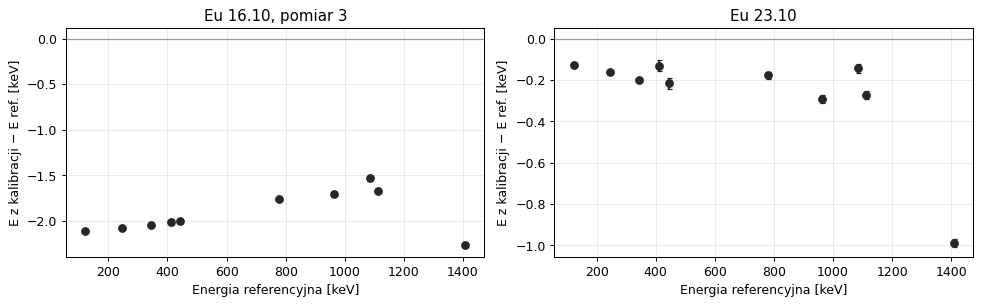

In [6]:
eu_lines=pd.DataFrame([
    # Energia i intensywność [%] przepisane ze świadectwa BW/Z-62/154/17, s. 2.
    (121.8,28.4),(244.7,7.6),(344.3,26.6),(411.1,2.4),
    (444.0,3.1),(778.9,13.0),(867.4,4.2),(964.1,14.5),
    (1085.8,10.1),(1112.1,13.4),(1212.9,1.4),(1299.1,1.6),(1408.0,20.9)
],columns=["E_keV","I_proc"])
chosen=[121.8,244.7,344.3,411.1,444.0,778.9,964.1,1085.8,1112.1,1408.0]
eu_fit=pd.DataFrame([fit_row("Eu-152",EU16,E) for E in chosen])
eu23_fit=pd.DataFrame([fit_row("Eu-152",EU23,E) for E in chosen])
display(eu_fit.drop(columns="fit").round(3))
comparison=pd.DataFrame({
    "E_ref_keV":chosen,
    "odchylenie_16.10_keV":eu_fit.E_clb_keV.to_numpy()-np.array(chosen),
    "odchylenie_23.10_keV":eu23_fit.E_clb_keV.to_numpy()-np.array(chosen)})
display(comparison.round(3))
print("16.10: mediana przesunięcia =",np.median(comparison["odchylenie_16.10_keV"]),"keV")

fig,axs=plt.subplots(1,2,figsize=(11,3.5))
for ax,frame,label in [(axs[0],eu_fit,"Eu 16.10, pomiar 3"),(axs[1],eu23_fit,"Eu 23.10")]:
    ax.axhline(0,color="0.6",lw=1)
    ax.errorbar(frame.E_ref_keV,frame.E_clb_keV-frame.E_ref_keV,
                yerr=(a1*frame.u_kanal),fmt="o",color="0.15",capsize=2)
    ax.set(title=label,xlabel="Energia referencyjna [keV]",ylabel="E z kalibracji − E ref. [keV]")
plt.tight_layout()
plt.show()

In [7]:
refs=[("Cs-137","Cs137/",661.7,False),
      ("Co-60","Co60/",1173.2,False),
      ("Co-60","Co60/",1332.5,False),
      ("Mn-56 stary","mangan/Mn_zakres_1.",846.8,False),
      ("Mn-56 nowy","mangan/Mn_zakres_2.",846.8,True),
      ("Mn-56 nowy","mangan/Mn_zakres_2.",1810.7,True),
      ("Mn-56 nowy","mangan/Mn_zakres_2.",2113.1,True),
      ("Na-22","Na_zakres2/",511.0,True),
      ("Na-22","Na_zakres2/",1274.6,True),
      ("I","jod/",442.9,False)]
checks=[]
for label,prefix,E,new_range in refs:
    matches=[s for n,s in spectra.items() if n.startswith(prefix)]
    for spec in matches:
        try:
            r=fit_row(label,spec,E,window=8 if new_range else 12,tolerance=6)
            checks.append(dict(plik=spec["path"].relative_to(RAW).as_posix(),
                               linia=label, E_ref_keV=E,E_fit_keV=r["E_clb_keV"],
                               u_stat_keV=(a2 if new_range else a1)*r["u_kanal"],
                               N=r["pole"],N_u=r["u_pole"],
                               FWHM_keV=r["FWHM_keV"],D_ndf=r["D_ndf"]))
        except (ValueError,RuntimeError) as exc:
            print("Pominięto",label,E,spec["path"].name,exc)
checks=pd.DataFrame(checks)
checks["delta_keV"]=checks.E_fit_keV-checks.E_ref_keV
display(checks.round(3))
print("Centroidy Mn nowego zakresu wynikają z dopasowania, nie z maksimum pojedynczego kanału.")

,plik,linia,E_ref_keV,E_fit_keV,u_stat_keV,N,N_u,FWHM_keV,D_ndf,delta_keV
0,Cs137/Cs137_1_Z40_Nepravskaya.lst,Cs-137,661.7,662.429,0.002,542112.443,826.969,2.918,1145.720,0.729
1,Cs137/Cs137_2_Z40_Nepravskaya.lst,Cs-137,661.7,662.059,0.002,162894.701,416.622,2.062,545.817,0.359
2,Cs137/Cs137_3_Z40_Nepravskaya.lst,Cs-137,661.7,662.330,0.003,191326.113,475.931,2.604,552.597,0.630
3,Cs137/Cs137_4_Z40_Nepravskaya.lst,Cs-137,661.7,662.168,0.002,212192.803,482.101,2.185,587.541,0.468
4,Cs137/Cs137_5_Z40_Nepravskaya.lst,Cs-137,661.7,668.299,0.109,161323.428,12049.986,9.720,3.078,6.599
5,Co60/Co60_2_Z40_Nepravskaya.lst,Co-60,1173.2,1172.339,0.005,96868.422,351.617,3.070,146.081,-0.861
6,Co60/Co60_3_Z40_Nepravskaya.lst,Co-60,1173.2,1171.766,0.004,63955.741,265.140,2.329,33.426,-1.434
7,Co60/Co60_4_Z40_Nepravskaya.lst,Co-60,1173.2,1171.929,0.006,54265.711,253.768,2.695,50.350,-1.271
8,Co60/Co60_2_Z40_Nepravskaya.lst,Co-60,1332.5,1331.234,0.005,88807.851,329.121,3.258,137.484,-1.266
9,Co60/Co60_3_Z40_Nepravskaya.lst,Co-60,1332.5,1330.639,0.005,57782.508,247.540,2.476,68.730,-1.861


Centroidy Mn nowego zakresu wynikają z dopasowania, nie z maksimum pojedynczego kanału.


### Pole piku Eu po odjęciu tła

Od zliczeń Eu odejmujemy długi pomiar tła, przeskalowany stosunkiem czasów żywych. Do widma po odjęciu tła dopasowujemy Gaussa i proste lokalne kontinuum; raportujemy wyłącznie niepewność **pola netto** $u(N)$ uzyskaną z dopasowania. Pojedyncze surowe zliczenia pozostają liczbami całkowitymi.

Eu i tło były rejestrowane w różnych dniach. W widmie Eu centra linii są przesunięte o około 2 keV względem referencji; odejmowanie według numeru kanału jest przybliżeniem. Dlatego podajemy też porównanie pól z wariantem tylko z lokalnym kontinuum. Dla linii bez istotnego piku tła różnica jest mała; nie traktujemy tego jako precyzyjnego wyrównania dwóch osi energii.

In [8]:
alpha_eu=EU16["live"]/BG["live"]
def eu_area_after_background(reference_fit):
    f=reference_fit["fit"]
    x=f["x"]
    k=x.astype(int)
    n=EU16["counts"][k].astype(float)
    b=BG["counts"][k].astype(float)
    z=n-alpha_eu*b
    weights=1/np.sqrt(np.maximum(n+alpha_eu**2*b,1))
    def model(q):
        A,mu,sig,B,slope=q
        return (A*(ndtr((x+.5-mu)/sig)-ndtr((x-.5-mu)/sig))
                +B+slope*(x-f["mu"]))
    q0=[f["A"],f["mu"],f["sigma"],f["bg"]-alpha_eu*np.median(b),f["slope"]]
    lo=[0.,f["mu"]-2.,.35,-np.inf,-np.inf]
    hi=[1e7,f["mu"]+2.,6.,np.inf,np.inf]
    fit=least_squares(lambda q:(z-model(q))*weights,q0,bounds=(lo,hi),max_nfev=5000)
    u_N=np.sqrt(max(np.linalg.pinv(fit.jac.T@fit.jac)[0,0],0))
    return dict(E_keV=reference_fit["E_ref_keV"],N_lokalne=f["A"],
                N_netto=fit.x[0],u_N_netto=u_N,
                zmiana_N=fit.x[0]-f["A"],
                zmiana_w_jednostkach_u=(fit.x[0]-f["A"])/f["u_A"])

eu_net=pd.DataFrame([eu_area_after_background(row) for _,row in eu_fit.iterrows()])
display(eu_net.round(3))
print("Maksymalna zmiana dla linii do krzywej widoczna w tabeli; skala tła:",alpha_eu)

,E_keV,N_lokalne,N_netto,u_N_netto,zmiana_N,zmiana_w_jednostkach_u
0,121.8,31684.346,31705.594,186.654,21.248,0.114
1,244.7,5434.632,5441.973,83.973,7.341,0.087
2,344.3,14511.179,14527.718,125.250,16.539,0.132
3,411.1,1024.593,1026.071,41.128,1.478,0.036
4,444.0,1432.105,1435.053,45.324,2.948,0.065
5,778.9,3468.580,3467.031,63.556,-1.549,-0.024
6,964.1,3199.005,3201.105,59.903,2.100,0.035
7,1085.8,2032.115,2118.918,49.928,86.803,1.719
8,1112.1,2751.194,2757.334,55.666,6.140,0.110
9,1408.0,3549.989,3526.670,60.120,-23.319,-0.385


Maksymalna zmiana dla linii do krzywej widoczna w tabeli; skala tła: 0.007536817788045048


## 4. Aktywność Eu i wydajność dla 16,9 cm

Aktywność w dniu 16.10.2026 oblicza się z $A=A_0 2^{-\Delta t/T_{1/2}}$. Świadectwo podaje $A_0=(101,3\pm2,4)$ kBq i $T_{1/2}=(13,522\pm0,016)$ roku, ale widoczna strona nie wyjaśnia współczynnika rozszerzenia niepewności. Wariant $k=1$ traktuje 2,4 kBq jako standardową, wariant $k=2$ jako rozszerzoną. Niepewności prawdopodobieństw $I_\gamma$ nie są dostępne w świadectwie; pokazane niepewności punktów są zatem **warunkowe**.

Dopasowanie z Z40 ma postać $\ln\varepsilon=c_3(\ln E)^3+c_2(\ln E)^2+c_1\ln E+c_0$ przy $E$ w keV. Model służy do interpolacji w obrębie linii Eu. Przyjęto $I_\gamma$ i czas żywy jako dokładne dane wejściowe. Niepewność punktowej wydajności obliczono z $u(N)$ i $u(A)$: $u(\varepsilon)=\varepsilon\sqrt{[u(N)/N]^2+[u(A)/A]^2}$. W geometrii kontaktowej wymaga to oddzielnego transferu.

In [9]:
from datetime import timedelta
A0=101300.0
uA0_quoted=2400.0
T_year=13.522
uT_year=.016
t0=datetime(2018,1,1,12,0)
dt_year=(EU16["date"]-t0).total_seconds()/(365.25*86400)
activity=A0*2**(-dt_year/T_year)
def activity_uncertainty(k_factor):
    uA0=uA0_quoted/k_factor
    dA_dA0=activity/A0
    dA_dT=activity*np.log(2)*dt_year/T_year**2
    return np.hypot(dA_dA0*uA0,dA_dT*uT_year)
uA_k1=activity_uncertainty(1)
uA_k2=activity_uncertainty(2)
print(f"Delta t={dt_year:.6f} roku; A_Eu={activity:.2f} Bq, u(A) przy k=1: {uA_k1:.2f} Bq, przy k=2: {uA_k2:.2f} Bq")
print("Zmiana względna aktywności w trakcie 526 s:",1-np.exp(-np.log(2)*EU16["real"]/(T_year*365.25*86400)))

eu_points=eu_fit.merge(eu_lines,left_on="E_ref_keV",right_on="E_keV")
eu_points=eu_points.merge(eu_net[["E_keV","N_netto","u_N_netto"]],on="E_keV")
eu_points["pole"]=eu_points.N_netto
eu_points["u_pole"]=eu_points.u_N_netto
eu_points["epsilon"]=eu_points.pole/(activity*(eu_points.I_proc/100)*EU16["live"])
eu_points["u_stat_epsilon"]=eu_points.epsilon*eu_points.u_pole/eu_points.pole
eu_points["u_cond_k1"]=eu_points.epsilon*np.hypot(eu_points.u_pole/eu_points.pole,uA_k1/activity)
eu_points["do_krzywej"]=eu_points.D_ndf<=5
display(eu_points[["E_keV","I_proc","pole","u_pole","FWHM_keV","D_ndf",
                    "epsilon","u_stat_epsilon","u_cond_k1","do_krzywej"]].round(6))
assert (eu_points.epsilon.between(0,1)).all()
print("Odrzucone z krzywej z powodu dewiancji > 5/ndf:",
      eu_points.loc[~eu_points.do_krzywej,"E_keV"].tolist())

curve_points=eu_points.loc[eu_points.do_krzywej]
x=np.log(curve_points.E_keV.to_numpy())
y=np.log(curve_points.epsilon.to_numpy())
X=np.column_stack([x**3,x**2,x,np.ones_like(x)])
frac_stat=(curve_points.u_pole/curve_points.pole).to_numpy()
coef=np.polyfit(x,y,3,w=1/frac_stat)
resid=(y-X@coef)/frac_stat
chi2_eff=float(resid@resid)
dof_eff=len(x)-4
print("Współczynniki c3,c2,c1,c0:",coef)
print("χ²/ndf (tylko niepewności pól):",chi2_eff/dof_eff)
def epsilon_at(E,k_factor=1):
    val=np.exp(np.polyval(coef,np.log(E)))
    closest=curve_points.iloc[np.argmin(abs(curve_points.E_keV.to_numpy()-E))]
    u_nearest=closest.u_pole/closest.pole
    uA=activity_uncertainty(k_factor)
    return val,val*np.hypot(u_nearest,uA/activity)
print("ε_Eu(411.8 keV), k=1:",epsilon_at(411.8))

Eplot=np.linspace(curve_points.E_keV.min(),curve_points.E_keV.max(),400)
fig,ax=plt.subplots()
ax.errorbar(curve_points.E_keV,curve_points.epsilon,yerr=curve_points.u_stat_epsilon,
            fmt="o",capsize=2,color="0.1",label="Eu użyte do krzywej")
excluded=eu_points.loc[~eu_points.do_krzywej]
ax.plot(excluded.E_keV,excluded.epsilon,"o",mfc="white",mec="0.2",label="złe dopasowanie piku")
ax.plot(Eplot,[epsilon_at(e)[0] for e in Eplot],color="0.45",label="Wielomian z Z40")
ax.set(xlabel="Energia fotonu [keV]",ylabel="Wydajność pełnoenergetyczna",yscale="log")
ax.legend();plt.show()

Delta t=8.788655 roku; A_Eu=64558.63 Bq, u(A) przy k=1: 1529.91 Bq, przy k=2: 765.54 Bq
Zmiana względna aktywności w trakcie 526 s: 8.544096031792847e-07


,E_keV,I_proc,pole,u_pole,FWHM_keV,D_ndf,epsilon,u_stat_epsilon,u_cond_k1,do_krzywej
0,121.8,28.4,31705.594268,186.653515,1.401278,6.963329,0.003313,0.000020,0.000081,False
1,244.7,7.6,5441.973456,83.972827,1.510817,1.196439,0.002125,0.000033,0.000060,True
2,344.3,26.6,14527.718022,125.250479,1.579166,4.189494,0.001621,0.000014,0.000041,True
3,411.1,2.4,1026.071274,41.128255,1.537592,2.057910,0.001269,0.000051,0.000059,True
4,444.0,3.1,1435.053089,45.323987,1.590257,1.625071,0.001374,0.000043,0.000054,True
5,778.9,13.0,3467.030710,63.556179,1.934345,1.464128,0.000791,0.000015,0.000024,True
6,964.1,14.5,3201.105068,59.902955,2.052581,2.145115,0.000655,0.000012,0.000020,True
7,1085.8,10.1,2118.918482,49.927787,2.057585,16.763834,0.000623,0.000015,0.000021,False
8,1112.1,13.4,2757.334021,55.666383,2.157959,3.509376,0.000611,0.000012,0.000019,True
9,1408.0,20.9,3526.669727,60.119772,2.459483,4.195276,0.000501,0.000009,0.000015,True


Odrzucone z krzywej z powodu dewiancji > 5/ndf: [121.8, 1085.8]
Współczynniki c3,c2,c1,c0: [  0.07871145  -1.48187671   8.41360161 -20.6972412 ]
χ²/ndf (tylko niepewności pól): 2.6779424919993677
ε_Eu(411.8 keV), k=1: (np.float64(0.0013887169786827253), np.float64(6.466503363192844e-05))


## 5. Tło i linia Au około 412 keV

Tło ma 2048 kolejnych kanałów i starą kalibrację. W widmach folii pokazano tło przeskalowane przez $t_{l,\rm próbka}/t_{l,\rm tło}$. Przy dopasowaniu pola piku użyto nieujemnych surowych zliczeń i lokalnego kontinuum w modelu Poissona. Skalowanego tła nie potraktowano jako bezszumowej wielkości. Wskazanie 511 keV w Cu jest nieswoiste i służy tylko kontroli jakościowej.

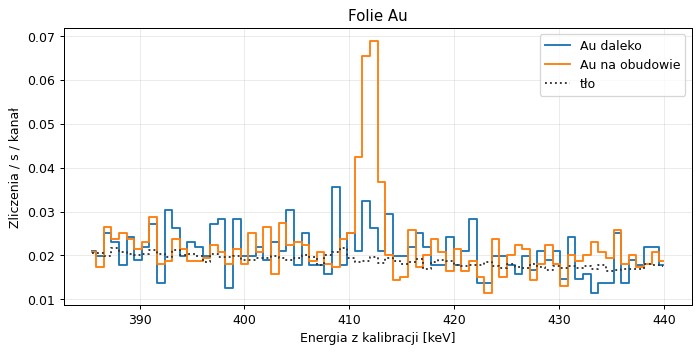

,widmo,E_fit_keV,pole,u_pole,S_do_u,gorny_limit_95
0,Au daleko,NaN,17.553,NaN,NaN,35.599
1,Au kontakt,411.928,193.726,19.924,9.723,NaN
2,Cu 511,511.141,289.797,24.286,11.933,NaN


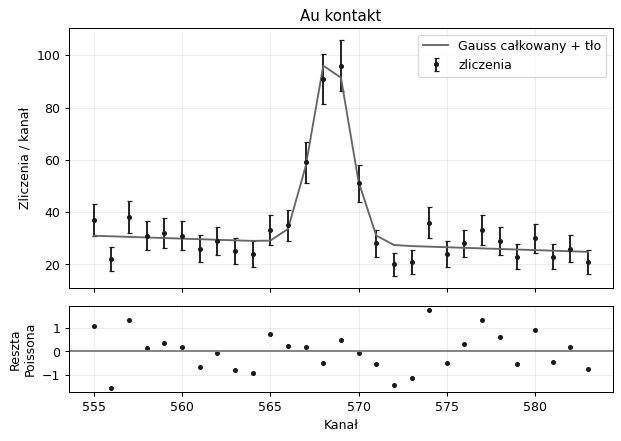

Au daleko okno 7 kanałów: 35.5 +/- 12.9 zliczeń; alfa= 0.013789
Au kontakt okno 7 kanałów: 204.3 +/- 19.9 zliczeń; alfa= 0.020098
Cu 511 okno 7 kanałów: 97.6 +/- 21.7 zliczeń; alfa= 0.026263


In [10]:
def overlay(specs, e_min, e_max, title, background=False):
    fig,ax=plt.subplots(figsize=(9,4))
    for label,s in specs:
        m=(s["energy"]>=e_min)&(s["energy"]<=e_max)
        ax.step(s["energy"][m],s["counts"][m]/s["live"],where="mid",label=label)
    if background:
        m=(BG["energy"]>=e_min)&(BG["energy"]<=e_max)
        ax.step(BG["energy"][m],BG["counts"][m]/BG["live"],where="mid",
                color="0.2",linestyle=":",label="tło")
    ax.set(xlabel="Energia z kalibracji [keV]",ylabel="Zliczenia / s / kanał",title=title)
    ax.legend();plt.show()

overlay([("Au daleko",AU1),("Au na obudowie",AU2)],385,440,"Folie Au",True)
overlay([("Cu na obudowie",CU)],492,530,"Obszar 511 keV w Cu",True)

au2=fit_row("Au-198",AU2,411.8,window=14,tolerance=5)
cu511=fit_row("511 keV, nieswoiste",CU,511.,window=14,tolerance=5)

def fixed_shape_upper_limit(spec, mu, sigma, half_window=14):
    # Dla słabego Au kształt i środek ustalono z pomiaru kontaktowego.
    x=spec["channel"]
    mask=abs(x-mu)<=half_window
    xx=x[mask].astype(float)
    yy=spec["counts"][mask].astype(float)
    shape=ndtr((xx+.5-mu)/sigma)-ndtr((xx-.5-mu)/sigma)
    offset=xx-mu
    def nll(A,B,slope):
        pred=A*shape+B+slope*offset
        if np.any(pred<=0): return 1e12+np.sum(np.maximum(-pred,0))*1e12
        return float(np.sum(pred-yy*np.log(pred)))
    bg0=float(np.median(np.r_[yy[:5],yy[-5:]]))
    bounds=[(0,None),(1e-5,None),(-10,10)]
    best=minimize(lambda q:nll(*q),[max(1.,yy.sum()-len(yy)*bg0),bg0,0.],
                  bounds=bounds,method="L-BFGS-B")
    if not best.success: raise RuntimeError(best.message)
    A0,B0,s0=best.x
    def profile(A):
        q=minimize(lambda bs:nll(A,*bs),[B0,s0],
                   bounds=bounds[1:],method="L-BFGS-B")
        if not q.success: raise RuntimeError(q.message)
        return 2*(q.fun-best.fun)
    upper=float(brentq(lambda A:profile(A)-2.705543,
                       A0,A0+max(100.,20*np.sqrt(yy.sum()))))
    return dict(A=A0,upper95=upper,x=xx,y=yy,
                pred=A0*shape+B0+s0*offset)

au1_limit=fixed_shape_upper_limit(AU1,au2["fit"]["mu"],au2["fit"]["sigma"])
au_table=pd.DataFrame([
    dict(widmo="Au daleko", E_fit_keV=np.nan,pole=au1_limit["A"],
         u_pole=np.nan, S_do_u=np.nan, gorny_limit_95=au1_limit["upper95"]),
    *[dict(widmo=name,E_fit_keV=r["E_clb_keV"],pole=r["pole"],
           u_pole=r["u_pole"],S_do_u=r["pole"]/r["u_pole"],
           gorny_limit_95=np.nan)
      for name,r in [("Au kontakt",au2),("Cu 511",cu511)]]])
display(au_table.round(3))
for name,f in [("Au daleko",au1_limit),("Au kontakt",au2["fit"])]:
    fig,axs=plt.subplots(2,1,figsize=(7,5),sharex=True,
                         gridspec_kw={"height_ratios":[3,1]})
    axs[0].errorbar(f["x"],f["y"],yerr=np.sqrt(np.maximum(f["y"],1)),fmt="o",
                    ms=3,capsize=2,color="0.1",label="zliczenia")
    axs[0].plot(f["x"],f["pred"],color="0.4",label="Gauss całkowany + tło")
    axs[0].set(ylabel="Zliczenia / kanał",title=name);axs[0].legend()
    residual=(f["y"]-f["pred"])/np.sqrt(np.maximum(f["pred"],1))
    axs[1].plot(f["x"],residual,"o",color="0.1",ms=3)
    axs[1].axhline(0,color="0.5")
    axs[1].set(xlabel="Kanał",ylabel="Reszta\nPoissona")
    plt.tight_layout();plt.show()

# Weryfikacja odjęcia tła w prostym oknie — diagnostyka, nie zamiennik dopasowania.
for label,spec in [("Au daleko",AU1),("Au kontakt",AU2),("Cu 511",CU)]:
    target=511 if label.startswith("Cu") else 411.8
    k=int(round((target-b1)/a1))
    indices=np.arange(k-3,k+4)
    alpha=spec["live"]/BG["live"]
    excess=np.sum(spec["counts"][indices]-alpha*BG["counts"][indices])
    u_excess=np.sqrt(np.sum(spec["counts"][indices]+alpha**2*BG["counts"][indices]))
    print(label,"okno 7 kanałów:",round(excess,1),"+/-",round(u_excess,1),
          "zliczeń; alfa=",round(alpha,6))

## 6. Strumień lokalny z Au: scenariusze

Z40 używa modelu aktywacji cienkiej folii:

$$N_\gamma=\frac{t_l}{t_r}\,\varepsilon I_\gamma\,
\frac{\sigma\phi m g N_A}{M\lambda}
(1-e^{-\lambda t_a})e^{-\lambda t_c}(1-e^{-\lambda t_r}).$$

Przyjęto dane Au z [dodatkowej instrukcji, Załącznik 3](../../instructions/Aktywacja_neutronowa_mat_dodatkowe.pdf): $\sigma=98,8$ b dla neutronów termicznych, $T_{1/2}=232675,2$ s, $g=1$, $I_\gamma=0,95$, $M=196,967$ g/mol oraz masę $m=0,1328$ g z etykiety. Liczby $I_\gamma$, $\sigma$, czas napromieniania i głębokość efektywna nie mają tu podanej standardowej niepewności. Otrzymane $u_{\rm war.}$ obejmuje tylko pole Au i wydajność Eu (w wariancie $k=1$), więc **nie jest pełną niepewnością fizyczną**.

Załącznik 1 tej instrukcji podaje gotową krzywą wydajności tego modelu detektora dla **źródła objętościowego o średnicy zbliżonej do detektora i wysokości około 4 cm**. Nie odpowiada ona punktowemu Eu na 16,9 cm ani folii w kontakcie. Wydrukowane tam równanie ma zamienione role $\ln E$ i $\ln\varepsilon$ względem opisu i osi wykresu. Nie przenosi się tych współczynników do niniejszej geometrii. W Załączniku 3 energia linii I jest podana jako 442,9 keV. Wpis $T_{1/2}=154,8$ s dla Mn jest sprzeczny z [danymi IAEA: 2,5789 h](https://www-nds.iaea.org/publications/indc/indc-ccp-0460.pdf) i nie służy do obliczeń zaniku.

Dla przekazu geometrii zastosowano jedynie scenariusz $G=[(16,9+d_0)/d_0]^2$, gdzie $d_0$ to efektywna głębokość pod obudową, a nie zmierzona szczelina. Gdy $\varepsilon_{\rm Eu}G>1$, scenariusz jest sprzeczny z definicją wydajności. Bliska geometria skończonej folii i kryształu może naruszać prawo $1/r^2$, nawet gdy wynik jest mniejszy od jedności. Nie dopasowuje się $d_0$ do emisji źródła.

,d0_cm,G,epsilon_contact,phi_n_cm2_s,u_war_n_cm2_s,dopuszczalna_wydajnosc
0,1.0,320.4100,0.4450,223.9631,25.2843,True
1,1.5,150.4711,0.2090,476.9022,53.8399,True
2,2.0,89.3025,0.1240,803.5610,90.7180,True
3,2.5,60.2176,0.0836,1191.6782,134.5345,True
4,3.0,44.0011,0.0611,1630.8680,184.1168,True
5,4.0,27.3006,0.0379,2628.5113,296.7457,True
6,5.0,19.1844,0.0266,3740.5393,422.2881,True


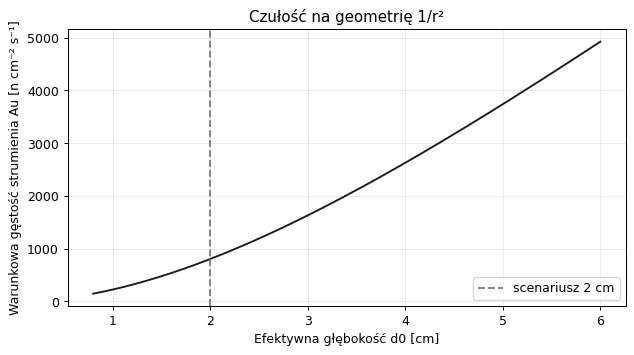

In [11]:
N_A=6.02214076e23
m_Au=.1328
M_Au=196.967
g_Au=1.
sigma_Au=98.8e-24
T_Au=232675.2
I_Au=.95
lam_Au=np.log(2)/T_Au
E_Au=411.8
d_Eu=16.9
t_a_nom=3.5*3600
t_c_Au2=1084.

def flux_Au(area,epsilon,ta=t_a_nom,tc=t_c_Au2,real=AU2["real"],live=AU2["live"]):
    return (area/epsilon/I_Au *real/live
            *M_Au*lam_Au/(sigma_Au*m_Au*g_Au*N_A)
            *np.exp(lam_Au*tc)
            /(-np.expm1(-lam_Au*ta))
            /(-np.expm1(-lam_Au*real)))

eps_Eu,u_eps_Eu=epsilon_at(E_Au,1)
scenarios=[]
for d0 in [1.,1.5,2.,2.5,3.,4.,5.]:
    G=((d_Eu+d0)/d0)**2
    eps=eps_Eu*G
    valid=eps<=1
    phi=flux_Au(au2["pole"],eps) if valid else np.nan
    u_cond=phi*np.hypot(au2["u_pole"]/au2["pole"],u_eps_Eu/eps_Eu) if valid else np.nan
    scenarios.append(dict(d0_cm=d0,G=G,epsilon_contact=eps,
                          phi_n_cm2_s=phi,u_war_n_cm2_s=u_cond,
                          dopuszczalna_wydajnosc=valid))
scenario_table=pd.DataFrame(scenarios)
display(scenario_table.round(4))

d0=np.linspace(.8,6,250)
G=((d_Eu+d0)/d0)**2
valid=eps_Eu*G<=1
phi=np.array([flux_Au(au2["pole"],eps_Eu*factor) if ok else np.nan
              for factor,ok in zip(G,valid)])
fig,ax=plt.subplots()
ax.plot(d0,phi,color="0.1")
ax.axvline(2,color="0.5",ls="--",label="scenariusz 2 cm")
ax.set(xlabel="Efektywna głębokość d0 [cm]",
       ylabel="Warunkowa gęstość strumienia Au [n cm⁻² s⁻¹]",
       title="Czułość na geometrię 1/r²")
ax.legend();plt.show()

### Przeliczenie geometrii z charakterystyki detektora

Załącznik 2, [karta tego konkretnego detektora ORTEC GMX25P4-70](../../instructions/charakterystyka_detektora_GMX25P4-70.png), podaje średnicę kryształu $53$ mm (promień $R=2,65$ cm), długość $70$ mm, odstęp $3$ mm przy przednim oknie, okno $0,03$ mm Al/Mylar i cienką przednią warstwę martwą Ge/B. Dla osiowego źródła punktowego przed płaskim dyskiem ułamek pełnego kąta bryłowego to

$$f(h,R)=\frac{\Omega}{4\pi}=\frac12\left(1-\frac{h}{\sqrt{h^2+R^2}}\right).$$

W wariancie geometrycznym przyjęto $h_{\rm Eu}=16,9+0,3$ cm i $h_{\rm Au}=0,3$ cm, czyli środek emisji folii na powierzchni zewnętrznej okna. Stosunek $G_\Omega=f(h_{\rm Au},R)/f(h_{\rm Eu},R)$ zastępuje przybliżenie odwrotnych kwadratów odległości. Dalsze wiersze pokazują wpływ **dodatkowego, niezmierzonego przesunięcia efektywnej płaszczyzny pochłaniania**. Nie należy interpretować go jako dokładnego położenia reakcji w Ge.

To jest **wyłącznie transfer geometryczny**, zakładający, że prawdopodobieństwo pełnego pochłonięcia fotonu padającego pod różnymi kątami jest takie samo. W bliskiej geometrii założenie może być złe. Skończona powierzchnia folii, oprawa Eu, osłona i rozpraszanie także nie są uwzględnione. Podane w karcie „relative efficiency 28%” dotyczy linii Co-60 przy 1,33 MeV i standardowej geometrii testowej. Nie jest bezwzględną wydajnością dla 412 keV w kontakcie z obudową.

In [12]:
R_Ge=53/20  # promień w cm
front_gap=.3  # 3 mm w cm
def solid_fraction(h,R=R_Ge):
    return .5*(1-h/np.sqrt(h*h+R*R))

geom_rows=[]
for extra_depth in [0.,.5,1.,2.]:
    h_Au=front_gap+extra_depth
    h_Eu=d_Eu+front_gap+extra_depth
    G_solid=solid_fraction(h_Au)/solid_fraction(h_Eu)
    eps=eps_Eu*G_solid
    phi=flux_Au(au2["pole"],eps)
    u_war=phi*np.hypot(au2["u_pole"]/au2["pole"],u_eps_Eu/eps_Eu)
    geom_rows.append(dict(dodatkowa_glebokosc_cm=extra_depth,h_Au_cm=h_Au,
                          h_Eu_cm=h_Eu,G_omega=G_solid,
                          epsilon_Au=eps,phi_n_cm2_s=phi,u_war_n_cm2_s=u_war))
geom_table=pd.DataFrame(geom_rows)
display(geom_table.round(4))
G_geo=geom_rows[0]["G_omega"]
eps_geo=geom_rows[0]["epsilon_Au"]
phi_geo=geom_rows[0]["phi_n_cm2_s"]
u_phi_geo=geom_rows[0]["u_war_n_cm2_s"]
print(f"Model dysku, odstęp 3 mm: G={G_geo:.3f}, ε_Au={eps_geo:.5f}, "
      f"φ_Au=({phi_geo:.1f} ± {u_phi_geo:.1f}) n cm^-2 s^-1 (tylko u warunkowe).")

,dodatkowa_glebokosc_cm,h_Au_cm,h_Eu_cm,G_omega,epsilon_Au,phi_n_cm2_s,u_war_n_cm2_s
0,0.0,0.3,17.2,76.1058,0.1057,942.8978,106.4484
1,0.5,0.8,17.7,64.5028,0.0896,1112.5094,125.5967
2,1.0,1.3,18.2,53.6264,0.0745,1338.1470,151.0701
3,2.0,2.3,19.2,36.6873,0.0509,1955.9913,220.8216


Model dysku, odstęp 3 mm: G=76.106, ε_Au=0.10569, φ_Au=(942.9 ± 106.4) n cm^-2 s^-1 (tylko u warunkowe).


In [13]:
def time_sensitivity(ta_values=(3.,3.5,4.),tc_values=(1077.,1084.)):
    eps=eps_geo
    return pd.DataFrame([dict(t_a_h=ta,t_c_s=tc,
        phi_n_cm2_s=flux_Au(au2["pole"],eps,ta=ta*3600,tc=tc))
        for ta in ta_values for tc in tc_values])
display(time_sensitivity().round(3))

print("Niepewność strumienia obejmuje jedynie u(N_Au) i u(ε_Eu);"
      " wpływ niepewnej geometrii i czasu aktywacji pokazano jako osobne scenariusze.")

,t_a_h,t_c_s,phi_n_cm2_s
0,3.0,1077.0,1097.096
1,3.0,1084.0,1097.119
2,3.5,1077.0,942.878
3,3.5,1084.0,942.898
4,4.0,1077.0,827.218
5,4.0,1084.0,827.236


Niepewność strumienia obejmuje jedynie u(N_Au) i u(ε_Eu); wpływ niepewnej geometrii i czasu aktywacji pokazano jako osobne scenariusze.


## 7. Widma uzupełniające i kontrola zakresu

Wykresy pokazują zmierzone serie bez przypisywania niepotwierdzonych izotopów monetom. Widmo Mn po zmianie zakresu obejmuje około 847, 1811 i 2113 keV. I ma stary zakres. Wykres Cu w sekcji 5 pozostaje jakościowy.

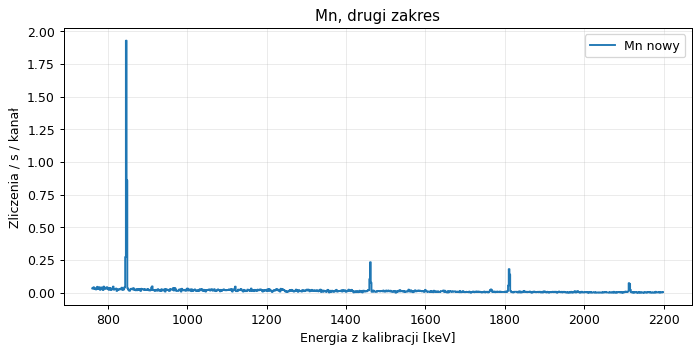

In [14]:
overlay([("Mn stary",S("mangan/Mn_zakres_1."))],780,900,"Mn około 847 keV")
overlay([("Mn nowy",MN2)],760,2200,"Mn, drugi zakres")
overlay([("I",S("jod/"))],410,480,"I, stary zakres")
overlay([("Moneta 1",COIN),("Moneta 2",S("moneta2/"))],150,1450,
        "Monety: widma w częstości zliczeń",True)
overlay([("Eu 16.10, pomiar 3",EU16)],90,1450,"Eu, geometria 16,9 cm")

## Co można przenieść do sprawozdania po zatwierdzeniu analizy

- Tabele czasów i dead time, dopasowane centroidy i pola Eu, Mn i Au oraz reszty kalibracji pochodzą z plików surowych.
- Krzywa wydajności Eu dotyczy wyłącznie jej geometrii. Wartość dla Au wymaga jawnego transferu.
- Wyniki $\phi$ dla scenariusza $d_0=2$ cm i dla modelu kąta bryłowego z Załącznika 2 są warunkowe. Rozrzut wariantów geometrii i aktywacji nie jest standardową niepewnością. Dane nie pozwalają utożsamić lokalnego $\phi$ z emisją $(7,7\pm1,5)\cdot10^5$ n/s źródła AmBe.
- Niepewność liczbowa $u(\phi)$ uwzględnia $u(N_{\rm Au})$ i $u(\varepsilon_{\rm Eu})$; pozostałe dane wejściowe przyjęto w tym rachunku jako zadane. Wpływ wyboru geometrii i czasu aktywacji przedstawiono jako scenariusze, bez przypisywania im sztucznej niepewności standardowej.